# Team 14 - LendingClub Loan Default and Profitability Prediction

**Course:** UE24CS352A - Machine Learning  
**Problem No.:** 39  
**Team:** Karan Varshney (PES2UG24CS903) and D Sai Karthik (PES2UG24CS141)


## 1. Setup and dataset download

The archive is large, so it is downloaded once with `kagglehub`. Only the accepted-loan file is used.

In [1]:
RUN_MODE = "TRAIN"   # "TRAIN" | "TEST" | "DEMO"

MODEL_DIR = "/content/drive/MyDrive/Team14_LendingClub/models"
RESULTS_DIR = "/content/drive/MyDrive/Team14_LendingClub/results"

print("Run mode:", RUN_MODE)

if RUN_MODE == "TRAIN":
    print("Training/validation mode: models will be fitted and saved.")
elif RUN_MODE == "TEST":
    print("Official evaluation mode: saved models will be run on the frozen held-out test sets.")
else:
    print("Demo mode: only the saved models and Gradio GUI will be used.")


Run mode: TRAIN
Training/validation mode: models will be fitted and saved.


### Quick-load saved models

In **DEMO** mode this cell mounts Google Drive and restores the fitted classifier, fitted regressor, thresholds and GUI defaults.  
Nothing is retrained.


In [2]:
if RUN_MODE in ["TEST", "DEMO"]:
    import os
    import json
    import joblib
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    from sklearn.metrics import (
        classification_report,
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        average_precision_score,
        roc_curve,
        precision_recall_curve,
        ConfusionMatrixDisplay,
        mean_squared_error,
        r2_score
    )

    from google.colab import drive
    drive.mount("/content/drive", force_remount=False)

    required_model_files = [
        "default_classifier.joblib",
        "nar_regressor.joblib",
        "model_config.joblib",
        "feature_defaults.joblib"
    ]

    missing_models = [
        name for name in required_model_files
        if not os.path.exists(os.path.join(MODEL_DIR, name))
    ]

    if missing_models:
        raise FileNotFoundError(
            "Saved model files are missing: "
            + ", ".join(missing_models)
            + "\nRun once with RUN_MODE='TRAIN'."
        )

    best_classifier = joblib.load(os.path.join(MODEL_DIR, "default_classifier.joblib"))
    best_regressor = joblib.load(os.path.join(MODEL_DIR, "nar_regressor.joblib"))
    config = joblib.load(os.path.join(MODEL_DIR, "model_config.joblib"))
    feature_defaults = joblib.load(os.path.join(MODEL_DIR, "feature_defaults.joblib"))

    best_threshold = float(config["default_threshold"])
    investment_threshold = float(config["investment_threshold"])
    best_classifier_name = config["best_classifier_name"]
    best_regressor_name = config["best_regressor_name"]
    feature_columns = config["feature_columns"]
    ui_options = config["ui_options"]

    print("Saved models loaded successfully.")
    print("Classifier:", best_classifier_name)
    print("Regressor:", best_regressor_name)
    print("Default threshold:", round(best_threshold, 4))
    print("Investment threshold:", round(investment_threshold, 4))

    if RUN_MODE == "TEST":
        test_path = os.path.join(MODEL_DIR, "heldout_test_sets.joblib")
        if not os.path.exists(test_path):
            raise FileNotFoundError(
                "Frozen test sets were not found. "
                "Run once with RUN_MODE='TRAIN' using this notebook."
            )

        test_bundle = joblib.load(test_path)
        X_test = test_bundle["X_test"]
        y_test = test_bundle["y_test"]
        Xr_test = test_bundle["Xr_test"]
        yr_test = test_bundle["yr_test"]

        print("Frozen held-out test sets loaded.")
        print("Classification test rows:", len(X_test))
        print("Regression test rows:", len(Xr_test))


In [3]:
if RUN_MODE == "TRAIN":
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)

    import kagglehub
    import os

    path = kagglehub.dataset_download("wordsforthewise/lending-club")
    print(path)
    print(os.listdir(path))


Using Colab cache for faster access to the 'lending-club' dataset.
/kaggle/input/lending-club
['rejected_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018Q4.csv.gz', 'accepted_2007_to_2018q4.csv', 'rejected_2007_to_2018q4.csv']


In [4]:
if RUN_MODE == "TRAIN":
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt

    pd.set_option("display.max_columns", 100)
    RANDOM_STATE = 42


## 2. Load the required columns

The full LendingClub file has many columns. We load only fields that are useful for the classification/regression tasks, plus the two fields needed later to calculate return.

### Main fields used
- `loan_amnt`, `funded_amnt`, `installment`: loan size and repayment amount
- `int_rate`, `grade`, `sub_grade`: LendingClub credit-risk information
- `annual_inc`, `dti`, `home_ownership`: borrower financial information
- `fico_range_low`, `fico_range_high`: credit-score range
- `delinq_2yrs`, `inq_last_6mths`, `pub_rec`, `revol_util`: credit-behaviour variables
- `term`, `emp_length`, `purpose`, `addr_state`: loan/borrower characteristics
- `total_pymnt`, `last_pymnt_d`: used **only** to construct the profitability target, never as classifier inputs


In [5]:
if RUN_MODE == "TRAIN":
    file_path = os.path.join(path, "accepted_2007_to_2018Q4.csv.gz")

    cols = [
        "loan_amnt",
        "funded_amnt",
        "term",
        "int_rate",
        "installment",
        "grade",
        "sub_grade",
        "emp_title",
        "emp_length",
        "home_ownership",
        "annual_inc",
        "verification_status",
        "issue_d",
        "loan_status",
        "purpose",
        "addr_state",
        "dti",
        "delinq_2yrs",
        "earliest_cr_line",
        "fico_range_low",
        "fico_range_high",
        "inq_last_6mths",
        "open_acc",
        "pub_rec",
        "revol_bal",
        "revol_util",
        "total_acc",
        "initial_list_status",
        "application_type",
        "mort_acc",
        "pub_rec_bankruptcies",
        "total_pymnt",
        "last_pymnt_d"
    ]


The file is read in chunks so that Colab does not have to keep the entire 2007-2018 dataset in memory. We keep only 2012-2015 loans with a final status.

In [6]:
if RUN_MODE == "TRAIN":
    final_status = ["Fully Paid", "Charged Off", "Default"]

    parts = []

    for chunk in pd.read_csv(
        file_path,
        usecols=cols,
        chunksize=100000,
        low_memory=False
    ):
        chunk["issue_d"] = pd.to_datetime(
            chunk["issue_d"],
            format="%b-%Y",
            errors="coerce"
        )

        chunk = chunk[
            chunk["issue_d"].dt.year.between(2012, 2015) &
            chunk["loan_status"].isin(final_status)
        ]

        parts.append(chunk)

    df = pd.concat(parts, ignore_index=True)

    df.shape


In [7]:
if RUN_MODE == "TRAIN":
    print(df.shape)
    display(df.head())
    df.info()


(786820, 33)


,loan_amnt,funded_amnt,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,total_pymnt,last_pymnt_d,application_type,mort_acc,pub_rec_bankruptcies
0,3600.0,3600.0,36 months,13.99,123.03,C,C4,leadman,10+ years,MORTGAGE,55000.0,Not Verified,2015-12-01,Fully Paid,debt_consolidation,PA,5.91,0.0,Aug-2003,675.0,679.0,1.0,7.0,0.0,2765.0,29.7,13.0,w,4421.723917,Jan-2019,Individual,1.0,0.0
1,24700.0,24700.0,36 months,11.99,820.28,C,C1,Engineer,10+ years,MORTGAGE,65000.0,Not Verified,2015-12-01,Fully Paid,small_business,SD,16.06,1.0,Dec-1999,715.0,719.0,4.0,22.0,0.0,21470.0,19.2,38.0,w,25679.660000,Jun-2016,Individual,4.0,0.0
2,20000.0,20000.0,60 months,10.78,432.66,B,B4,truck driver,10+ years,MORTGAGE,63000.0,Not Verified,2015-12-01,Fully Paid,home_improvement,IL,10.78,0.0,Aug-2000,695.0,699.0,0.0,6.0,0.0,7869.0,56.2,18.0,w,22705.924294,Jun-2017,Joint App,5.0,0.0
3,10400.0,10400.0,60 months,22.45,289.91,F,F1,Contract Specialist,3 years,MORTGAGE,104433.0,Source Verified,2015-12-01,Fully Paid,major_purchase,PA,25.37,1.0,Jun-1998,695.0,699.0,3.0,12.0,0.0,21929.0,64.5,35.0,w,11740.500000,Jul-2016,Individual,6.0,0.0
4,11950.0,11950.0,36 months,13.44,405.18,C,C3,Veterinary Tecnician,4 years,RENT,34000.0,Source Verified,2015-12-01,Fully Paid,debt_consolidation,GA,10.20,0.0,Oct-1987,690.0,694.0,0.0,5.0,0.0,8822.0,68.4,6.0,w,13708.948530,May-2017,Individual,0.0,0.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 786820 entries, 0 to 786819
Data columns (total 33 columns):
 #   Column                Non-Null Count   Dtype         
---  ------                --------------   -----         
 0   loan_amnt             786820 non-null  float64       
 1   funded_amnt           786820 non-null  float64       
 2   term                  786820 non-null  object        
 3   int_rate              786820 non-null  float64       
 4   installment           786820 non-null  float64       
 5   grade                 786820 non-null  object        
 6   sub_grade             786820 non-null  object        
 7   emp_title             740224 non-null  object        
 8   emp_length            745321 non-null  object        
 9   home_ownership        786820 non-null  object        
 10  annual_inc            786820 non-null  float64       
 11  verification_status   786820 non-null  object        
 12  issue_d               786820 non-null  datetime64[ns]
 13 

## 3. Define the classification target

`Fully Paid` is class 1. `Charged Off` and `Default` are class 0. Current or late loans were already removed because their final outcome is unknown.

In [8]:
if RUN_MODE == "TRAIN":
    print(df["loan_status"].value_counts())
    print()
    print(df["loan_status"].value_counts(normalize=True).mul(100).round(2))


loan_status
Fully Paid     640186
Charged Off    146632
Default             2
Name: count, dtype: int64

loan_status
Fully Paid     81.36
Charged Off    18.64
Default         0.00
Name: proportion, dtype: float64


In [9]:
if RUN_MODE == "TRAIN":
    df["target"] = df["loan_status"].map({
        "Fully Paid": 1,
        "Charged Off": 0,
        "Default": 0
    })

    print(df["target"].value_counts())
    print()
    print(df["target"].value_counts(normalize=True).mul(100).round(2))


target
1    640186
0    146634
Name: count, dtype: int64

target
1    81.36
0    18.64
Name: proportion, dtype: float64


In [10]:
if RUN_MODE == "TRAIN":
    df["outcome"] = df["target"].map({
        1: "Fully Paid",
        0: "Default"
    })

    df[["loan_status", "target", "outcome"]].head(10)


In [11]:
if RUN_MODE == "TRAIN":
    print("Rows:", len(df))
    print("Columns:", df.shape[1])
    print()
    print(df["issue_d"].dt.year.value_counts().sort_index())
    print()
    print(df["outcome"].value_counts())
    print()
    print(df["outcome"].value_counts(normalize=True).mul(100).round(2))


Rows: 786820
Columns: 35

issue_d
2012     53367
2013    134804
2014    223103
2015    375546
Name: count, dtype: int64

outcome
Fully Paid    640186
Default       146634
Name: count, dtype: int64

outcome
Fully Paid    81.36
Default       18.64
Name: proportion, dtype: float64


### Dataset check
The reference paper reported 745,529 finalized loans with roughly 81% positive and 19% negative examples. Our archived LendingClub file can contain a slightly different number of rows because it is a later snapshot. The important checks are that we use the same 2012-2015 period, remove unfinished loans and obtain a similar class distribution.


## 4. Basic cleaning and exploratory analysis

We first check missing values. `emp_title` is dropped because it is free-form text with a very large number of unique values. The paper also leaves free-form text analysis for future work.

In [12]:
if RUN_MODE == "TRAIN":
    missing = pd.DataFrame({
        "missing": df.isnull().sum(),
        "percent": df.isnull().mean().mul(100).round(2)
    })

    missing[missing["missing"] > 0].sort_values("percent", ascending=False)


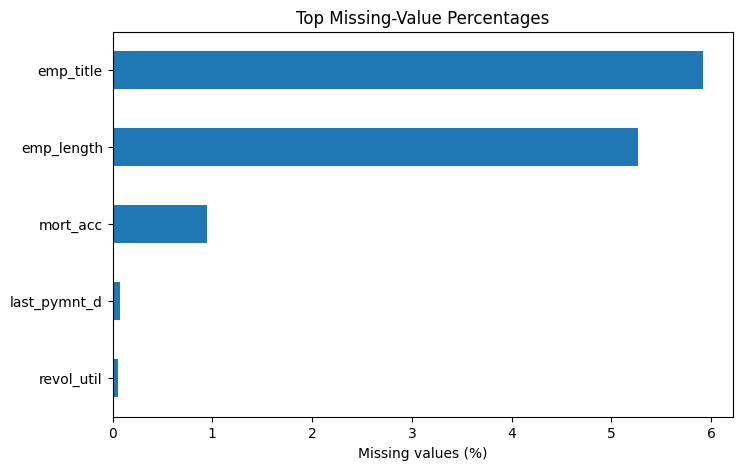

In [13]:
if RUN_MODE == "TRAIN":
    missing_plot = missing[missing["percent"] > 0].sort_values("percent", ascending=False).head(15)
    missing_plot["percent"].sort_values().plot(kind="barh", figsize=(8, 5), title="Top Missing-Value Percentages")
    plt.xlabel("Missing values (%)")
    plt.show()


In [14]:
if RUN_MODE == "TRAIN":
    # Free-form job titles create too many one-hot encoded columns.
    df = df.drop(columns=["emp_title"])


A few raw fields are converted into simpler numerical features: term length in months, employment length in years, and the midpoint of the FICO range.

In [15]:
if RUN_MODE == "TRAIN":
    df["term_months"] = (
        df["term"]
        .astype(str)
        .str.extract(r"(\d+)")
        .astype(float)
    )

    df["emp_length_num"] = (
        df["emp_length"]
        .replace({
            "< 1 year": "0",
            "10+ years": "10"
        })
        .astype(str)
        .str.extract(r"(\d+)")
        .astype(float)
    )

    df["fico_score"] = (
        df["fico_range_low"] + df["fico_range_high"]
    ) / 2


### Outcome distribution

This plot shows the class imbalance in the data. Most loans are fully paid, so accuracy alone will not be enough to judge a classifier.

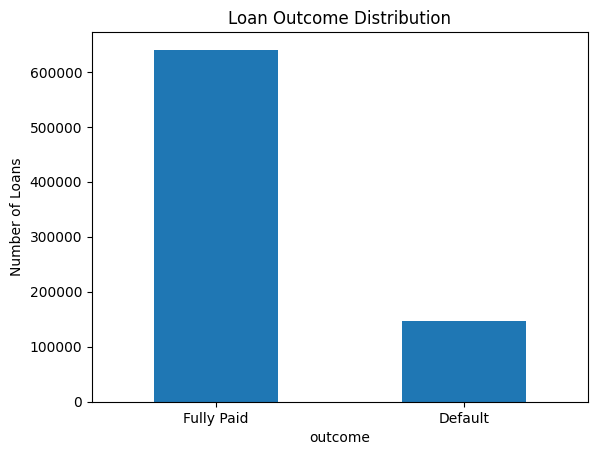

In [16]:
if RUN_MODE == "TRAIN":
    df["outcome"].value_counts().plot(
        kind="bar",
        title="Loan Outcome Distribution"
    )

    plt.ylabel("Number of Loans")
    plt.xticks(rotation=0)
    plt.show()


### Default rate by loan grade and term

These plots are useful sanity checks. Loan grade and loan term should show meaningful differences in repayment risk.

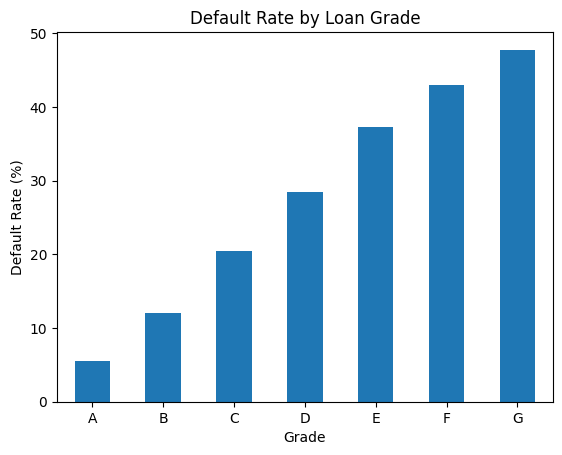

In [17]:
if RUN_MODE == "TRAIN":
    grade_default = (
        df.groupby("grade")["target"]
        .apply(lambda x: (1 - x).mean() * 100)
    )

    grade_default.plot(
        kind="bar",
        title="Default Rate by Loan Grade"
    )

    plt.ylabel("Default Rate (%)")
    plt.xlabel("Grade")
    plt.xticks(rotation=0)
    plt.show()


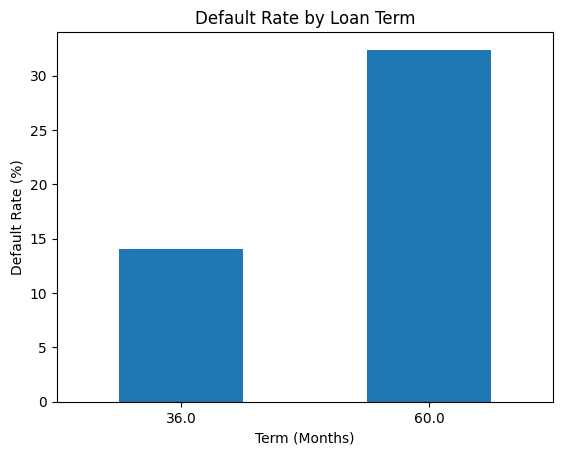

In [18]:
if RUN_MODE == "TRAIN":
    term_default = (
        df.groupby("term_months")["target"]
        .apply(lambda x: (1 - x).mean() * 100)
    )

    term_default.plot(
        kind="bar",
        title="Default Rate by Loan Term"
    )

    plt.ylabel("Default Rate (%)")
    plt.xlabel("Term (Months)")
    plt.xticks(rotation=0)
    plt.show()


### Numerical features versus outcome

The following boxplots compare interest rate, debt-to-income ratio and FICO score for fully paid and defaulted loans.

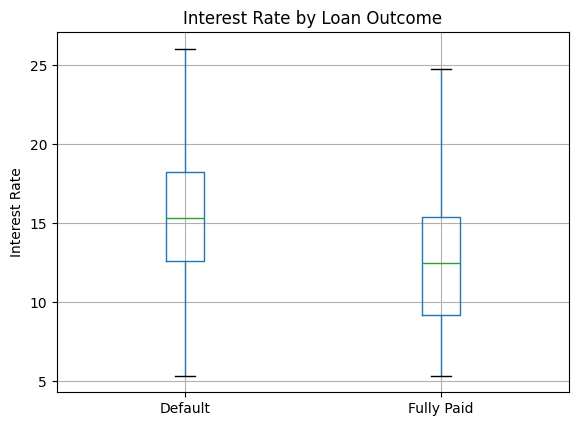

In [19]:
if RUN_MODE == "TRAIN":
    df.boxplot(
        column="int_rate",
        by="outcome",
        showfliers=False
    )

    plt.title("Interest Rate by Loan Outcome")
    plt.suptitle("")
    plt.xlabel("")
    plt.ylabel("Interest Rate")
    plt.show()


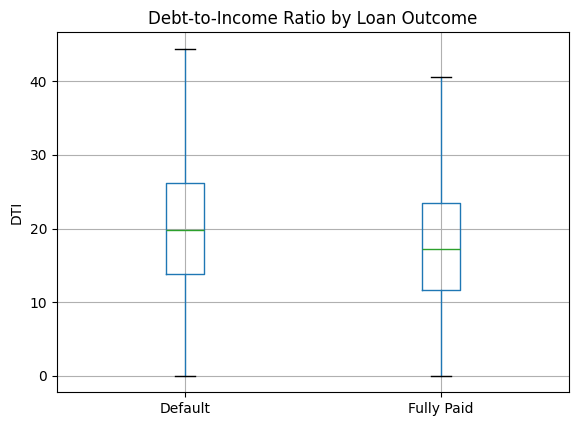

In [20]:
if RUN_MODE == "TRAIN":
    df.boxplot(
        column="dti",
        by="outcome",
        showfliers=False
    )

    plt.title("Debt-to-Income Ratio by Loan Outcome")
    plt.suptitle("")
    plt.xlabel("")
    plt.ylabel("DTI")
    plt.show()


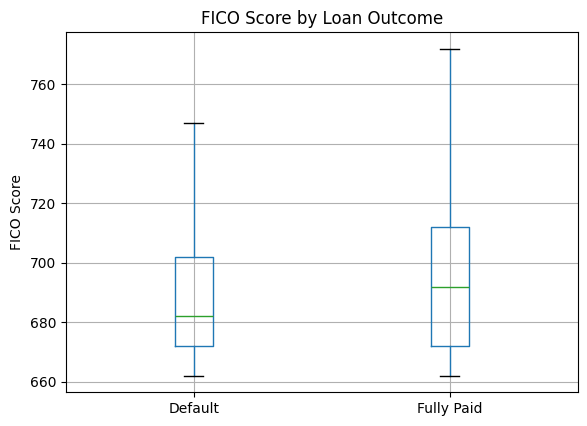

In [21]:
if RUN_MODE == "TRAIN":
    df.boxplot(
        column="fico_score",
        by="outcome",
        showfliers=False
    )

    plt.title("FICO Score by Loan Outcome")
    plt.suptitle("")
    plt.xlabel("")
    plt.ylabel("FICO Score")
    plt.show()


### Correlation among selected numerical features
The reference paper includes a numerical-feature correlation heatmap. We include a compact version here to identify strongly related variables before modelling.


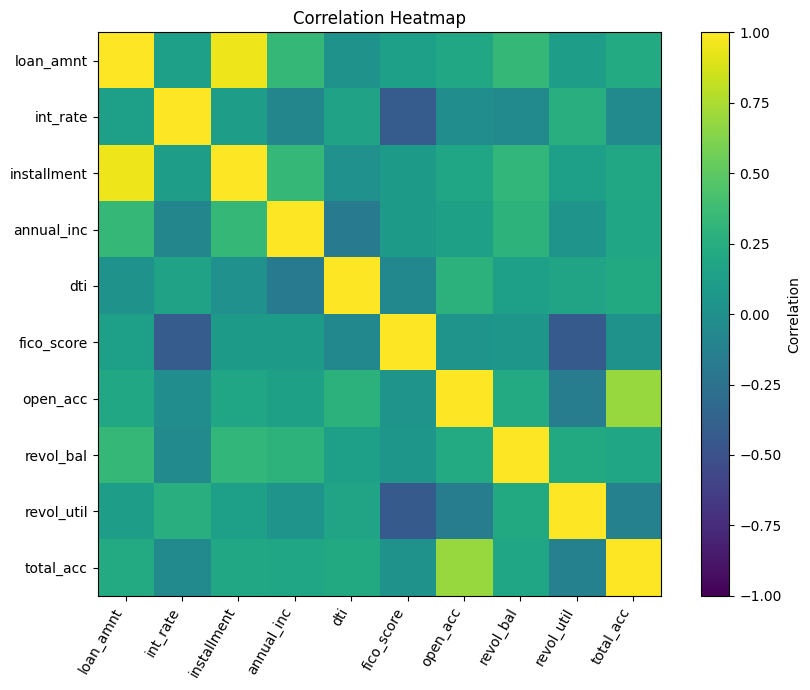

In [22]:
if RUN_MODE == "TRAIN":
    corr_cols = [
        "loan_amnt", "int_rate", "installment", "annual_inc", "dti",
        "fico_score", "open_acc", "revol_bal", "revol_util", "total_acc"
    ]

    corr = df[corr_cols].corr()
    fig, ax = plt.subplots(figsize=(9, 7))
    im = ax.imshow(corr, vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr_cols)))
    ax.set_yticks(range(len(corr_cols)))
    ax.set_xticklabels(corr_cols, rotation=60, ha="right")
    ax.set_yticklabels(corr_cols)
    fig.colorbar(im, ax=ax, label="Correlation")
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.show()


## 5. Build the classifier feature matrix

### Leakage rule
For the default classifier, every input must be information that is available at or near loan origination. `total_pymnt` and `last_pymnt_d` describe what happened after the loan was issued, so using them would leak the answer into the model.

They are retained in the original dataframe only because the profitability section later needs them to calculate NAR. They are explicitly excluded from `X` below.


In [23]:
if RUN_MODE == "TRAIN":
    drop_classifier = [
        "loan_status",
        "target",
        "outcome",
        "total_pymnt",
        "last_pymnt_d",
        "term",
        "emp_length",
        "fico_range_low",
        "fico_range_high"
    ]

    X = df.drop(columns=drop_classifier)
    y = df["target"]

    print(X.shape)
    print(y.shape)
    display(X.head())


(786820, 28)
(786820,)


,loan_amnt,funded_amnt,int_rate,installment,grade,sub_grade,home_ownership,annual_inc,verification_status,issue_d,purpose,addr_state,dti,delinq_2yrs,earliest_cr_line,inq_last_6mths,open_acc,pub_rec,revol_bal,revol_util,total_acc,initial_list_status,application_type,mort_acc,pub_rec_bankruptcies,term_months,emp_length_num,fico_score
0,3600.0,3600.0,13.99,123.03,C,C4,MORTGAGE,55000.0,Not Verified,2015-12-01,debt_consolidation,PA,5.91,0.0,Aug-2003,1.0,7.0,0.0,2765.0,29.7,13.0,w,Individual,1.0,0.0,36.0,10.0,677.0
1,24700.0,24700.0,11.99,820.28,C,C1,MORTGAGE,65000.0,Not Verified,2015-12-01,small_business,SD,16.06,1.0,Dec-1999,4.0,22.0,0.0,21470.0,19.2,38.0,w,Individual,4.0,0.0,36.0,10.0,717.0
2,20000.0,20000.0,10.78,432.66,B,B4,MORTGAGE,63000.0,Not Verified,2015-12-01,home_improvement,IL,10.78,0.0,Aug-2000,0.0,6.0,0.0,7869.0,56.2,18.0,w,Joint App,5.0,0.0,60.0,10.0,697.0
3,10400.0,10400.0,22.45,289.91,F,F1,MORTGAGE,104433.0,Source Verified,2015-12-01,major_purchase,PA,25.37,1.0,Jun-1998,3.0,12.0,0.0,21929.0,64.5,35.0,w,Individual,6.0,0.0,60.0,3.0,697.0
4,11950.0,11950.0,13.44,405.18,C,C3,RENT,34000.0,Source Verified,2015-12-01,debt_consolidation,GA,10.20,0.0,Oct-1987,0.0,5.0,0.0,8822.0,68.4,6.0,w,Individual,0.0,0.0,36.0,4.0,692.0


Before modelling, the date fields are converted into numerical information. Credit-history length is more useful than one-hot encoding every possible credit-start month.

In [24]:
if RUN_MODE == "TRAIN":
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

    print("Numeric:", len(numeric_cols))
    print(numeric_cols)

    print("\nCategorical:", len(categorical_cols))
    print(categorical_cols)


Numeric: 18
['loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'term_months', 'emp_length_num', 'fico_score']

Categorical: 10
['grade', 'sub_grade', 'home_ownership', 'verification_status', 'issue_d', 'purpose', 'addr_state', 'earliest_cr_line', 'initial_list_status', 'application_type']


In [25]:
if RUN_MODE == "TRAIN":
    X = X.copy()

    X["issue_year"] = X["issue_d"].dt.year
    X["issue_month"] = X["issue_d"].dt.month

    X["earliest_cr_line"] = pd.to_datetime(
        X["earliest_cr_line"],
        format="%b-%Y",
        errors="coerce"
    )

    X["credit_history_years"] = (
        (X["issue_d"] - X["earliest_cr_line"]).dt.days / 365.25
    )

    X = X.drop(columns=["issue_d", "earliest_cr_line"])


In [26]:
if RUN_MODE == "TRAIN":
    numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
    categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

    print("Numeric:", len(numeric_cols))
    print(numeric_cols)

    print("\nCategorical:", len(categorical_cols))
    print(categorical_cols)


Numeric: 21
['loan_amnt', 'funded_amnt', 'int_rate', 'installment', 'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'mort_acc', 'pub_rec_bankruptcies', 'term_months', 'emp_length_num', 'fico_score', 'issue_year', 'issue_month', 'credit_history_years']

Categorical: 8
['grade', 'sub_grade', 'home_ownership', 'verification_status', 'purpose', 'addr_state', 'initial_list_status', 'application_type']


## 6. Train, validation and test split

70% of the data is used for training, 15% for validation and 15% for final testing. Stratification keeps the paid/default ratio almost identical in all three sets.

In [27]:
if RUN_MODE == "TRAIN":
    from sklearn.model_selection import train_test_split

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        stratify=y,
        random_state=42
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=42
    )

    print("Train:", X_train.shape)
    print("Validation:", X_val.shape)
    print("Test:", X_test.shape)


Train: (550774, 29)
Validation: (118023, 29)
Test: (118023, 29)


In [28]:
if RUN_MODE == "TRAIN":
    for name, values in [("Train", y_train), ("Validation", y_val), ("Test", y_test)]:
        print(name)
        print(values.value_counts(normalize=True).mul(100).round(2))
        print()


Train
target
1    81.36
0    18.64
Name: proportion, dtype: float64

Validation
target
1    81.36
0    18.64
Name: proportion, dtype: float64

Test
target
1    81.36
0    18.64
Name: proportion, dtype: float64



## 7. Preprocessing pipeline

Numerical columns use median imputation followed by standardization. Categorical columns use the most frequent value for missing data and one-hot encoding. Everything is kept inside a scikit-learn pipeline so preprocessing is learned only from training data.

In [29]:
if RUN_MODE == "TRAIN":
    from sklearn.compose import ColumnTransformer
    from sklearn.pipeline import Pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import OneHotEncoder, StandardScaler


    def build_preprocessor():
        numeric_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ])

        categorical_transformer = Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ])

        return ColumnTransformer([
            ("num", numeric_transformer, numeric_cols),
            ("cat", categorical_transformer, categorical_cols)
        ])


### Development mode

Tree ensembles and neural networks can take time on the full training set. Keep `FAST_MODE = True` while checking the notebook. For the final reported results, set it to `False` and run the modelling sections again.

In [30]:
if RUN_MODE == "TRAIN":
    FAST_MODE = True
    MODEL_SAMPLE_SIZE = 200000

    if FAST_MODE and len(X_train) > MODEL_SAMPLE_SIZE:
        X_train_model, _, y_train_model, _ = train_test_split(
            X_train,
            y_train,
            train_size=MODEL_SAMPLE_SIZE,
            stratify=y_train,
            random_state=RANDOM_STATE
        )
    else:
        X_train_model = X_train
        y_train_model = y_train

    print("Model training rows:", len(X_train_model))


Model training rows: 200000


## Reference-paper classification benchmark
These are **paper results, not our results**. They are included only as a benchmark for discussion. Because our archived dataset and feature subset differ, exact replication is not expected.

| Model | Test Default F1 | Test Fully Paid F1 | Weighted performance |
|---|---:|---:|---:|
| Logistic Regression | 0.73 | 0.92 | about 0.88 |
| Neural Network | 0.72 | 0.93 | about 0.89 |
| Random Forest | 0.70 | 0.94 | about 0.89 |


## 8. Classification models

The reference paper compares Logistic Regression, a multilayer perceptron and Random Forest. A majority-class dummy model is added here as a baseline.

In [31]:
if RUN_MODE == "TRAIN":
    from sklearn.dummy import DummyClassifier
    from sklearn.linear_model import LogisticRegression
    from sklearn.neural_network import MLPClassifier
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.metrics import (
        accuracy_score,
        precision_score,
        recall_score,
        f1_score,
        roc_auc_score,
        average_precision_score,
        classification_report,
        ConfusionMatrixDisplay,
        roc_curve,
        precision_recall_curve
    )


    def classification_metrics(name, model, X_eval, y_eval):
        pred = model.predict(X_eval)
        paid_prob = model.predict_proba(X_eval)[:, 1]
        default_prob = 1 - paid_prob
        y_default = 1 - y_eval.to_numpy()

        return {
            "Model": name,
            "Accuracy": accuracy_score(y_eval, pred),
            "Default Precision": precision_score(y_eval, pred, pos_label=0, zero_division=0),
            "Default Recall": recall_score(y_eval, pred, pos_label=0, zero_division=0),
            "Default F1": f1_score(y_eval, pred, pos_label=0, zero_division=0),
            "Weighted F1": f1_score(y_eval, pred, average="weighted"),
            "ROC-AUC": roc_auc_score(y_default, default_prob),
            "PR-AUC": average_precision_score(y_default, default_prob)
        }


### 8.1 Dummy baseline

This model predicts the majority class every time. With an 81/19 class split it can still obtain high accuracy, which shows why recall, F1 and PR-AUC matter.

In [32]:
if RUN_MODE == "TRAIN":
    dummy_model = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", DummyClassifier(strategy="most_frequent"))
    ])

    dummy_model.fit(X_train_model, y_train_model)
    dummy_result = classification_metrics("Dummy", dummy_model, X_val, y_val)

    print(classification_report(
        y_val,
        dummy_model.predict(X_val),
        labels=[0, 1],
        target_names=["Default", "Fully Paid"],
        zero_division=0
    ))


              precision    recall  f1-score   support

     Default       0.00      0.00      0.00     21995
  Fully Paid       0.81      1.00      0.90     96028

    accuracy                           0.81    118023
   macro avg       0.41      0.50      0.45    118023
weighted avg       0.66      0.81      0.73    118023



### 8.2 Logistic Regression

Balanced class weights give more importance to the minority default class. This is close to the setup used in the paper.

In [33]:
if RUN_MODE == "TRAIN":
    log_model = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", LogisticRegression(
            class_weight="balanced",
            max_iter=500,
            solver="saga",
            random_state=RANDOM_STATE
        ))
    ])

    log_model.fit(X_train_model, y_train_model)
    log_result = classification_metrics("Logistic Regression", log_model, X_val, y_val)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


### 8.3 Neural Network

The hidden-layer sizes follow the reference paper. Early stopping is added so training stops when validation performance inside the training routine stops improving.

In [34]:
if RUN_MODE == "TRAIN":
    mlp_model = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", MLPClassifier(
            hidden_layer_sizes=(10, 10, 5, 3),
            activation="logistic",
            solver="adam",
            batch_size=200,
            learning_rate_init=0.001,
            alpha=0.0001,
            max_iter=60,
            early_stopping=True,
            n_iter_no_change=5,
            random_state=RANDOM_STATE
        ))
    ])

    mlp_model.fit(X_train_model, y_train_model)
    mlp_result = classification_metrics("Neural Network", mlp_model, X_val, y_val)


### 8.4 Random Forest

The paper used 200 trees and considered at most 50 features at each split. `balanced_subsample` reweights classes separately for each bootstrap sample.

In [ ]:
if RUN_MODE == "TRAIN":
    rf_trees = 100 if FAST_MODE else 200

    rf_model = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", RandomForestClassifier(
            n_estimators=rf_trees,
            max_features=50,
            class_weight="balanced_subsample",
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ])

    rf_model.fit(X_train_model, y_train_model)
    rf_result = classification_metrics("Random Forest", rf_model, X_val, y_val)


### 8.5 Compare classification models
Accuracy alone is not enough because around four-fifths of the loans are fully paid. We therefore report default precision, default recall, default F1, weighted F1, ROC-AUC and PR-AUC.

For model selection we use **default-class F1 on the validation set**, because it balances how many defaults are detected against how many safe loans are incorrectly flagged.


In [ ]:
if RUN_MODE == "TRAIN":
    classification_results = pd.DataFrame([
        dummy_result,
        log_result,
        mlp_result,
        rf_result
    ]).set_index("Model")

    classification_results.round(4)


In [ ]:
if RUN_MODE == "TRAIN":
    classification_results[["Default F1", "Default Recall", "Weighted F1"]].plot(
        kind="bar",
        figsize=(9, 5),
        title="Classification Model Comparison"
    )
    plt.ylabel("Score")
    plt.ylim(0, 1)
    plt.xticks(rotation=20)
    plt.show()


## 9. Choose a classifier and tune the decision threshold

The best non-dummy model is chosen using validation default F1. The default-probability threshold is also selected on the validation set only. The test set remains untouched until the final evaluation.

In [ ]:
if RUN_MODE == "TRAIN":
    class_models = {
        "Logistic Regression": log_model,
        "Neural Network": mlp_model,
        "Random Forest": rf_model
    }

    best_classifier_name = (
        classification_results.drop(index="Dummy")
        .sort_values("Default F1", ascending=False)
        .index[0]
    )
    best_classifier = class_models[best_classifier_name]

    val_default_prob = 1 - best_classifier.predict_proba(X_val)[:, 1]
    y_val_default = 1 - y_val.to_numpy()

    threshold_rows = []
    for threshold in np.linspace(0.10, 0.90, 81):
        pred_default = (val_default_prob >= threshold).astype(int)
        threshold_rows.append({
            "threshold": threshold,
            "f1": f1_score(y_val_default, pred_default),
            "precision": precision_score(y_val_default, pred_default, zero_division=0),
            "recall": recall_score(y_val_default, pred_default, zero_division=0)
        })

    threshold_results = pd.DataFrame(threshold_rows)
    best_threshold = threshold_results.loc[threshold_results["f1"].idxmax(), "threshold"]

    print("Best classifier:", best_classifier_name)
    print("Best default threshold:", round(best_threshold, 2))
    threshold_results.sort_values("f1", ascending=False).head()


### Final classification result on the test set

In [ ]:
if RUN_MODE == "TEST":
    test_default_prob = 1 - best_classifier.predict_proba(X_test)[:, 1]
    test_pred_default = (test_default_prob >= best_threshold).astype(int)
    test_pred = 1 - test_pred_default

    print(classification_report(
        y_test,
        test_pred,
        labels=[0, 1],
        target_names=["Default", "Fully Paid"],
        zero_division=0
    ))

    print("Test ROC-AUC:", round(roc_auc_score(1 - y_test.to_numpy(), test_default_prob), 4))
    print("Test PR-AUC:", round(average_precision_score(1 - y_test.to_numpy(), test_default_prob), 4))


In [ ]:
if RUN_MODE == "TEST":
    final_classification = pd.DataFrame({
        "Metric": ["ROC-AUC", "PR-AUC", "Default Precision", "Default Recall", "Default F1", "Weighted F1"],
        "Value": [
            roc_auc_score(1 - y_test.to_numpy(), test_default_prob),
            average_precision_score(1 - y_test.to_numpy(), test_default_prob),
            precision_score(y_test, test_pred, pos_label=0, zero_division=0),
            recall_score(y_test, test_pred, pos_label=0, zero_division=0),
            f1_score(y_test, test_pred, pos_label=0, zero_division=0),
            f1_score(y_test, test_pred, average="weighted")
        ]
    })
    final_classification.round(4)


In [ ]:
if RUN_MODE == "TEST":
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_pred,
        display_labels=["Default", "Fully Paid"]
    )
    plt.title(f"{best_classifier_name} - Test Set")
    plt.show()


In [ ]:
if RUN_MODE == "TEST":
    y_test_default = 1 - y_test.to_numpy()
    fpr, tpr, _ = roc_curve(y_test_default, test_default_prob)
    precision, recall, _ = precision_recall_curve(y_test_default, test_default_prob)

    test_roc_auc = roc_auc_score(y_test_default, test_default_prob)
    test_pr_auc = average_precision_score(y_test_default, test_default_prob)

    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - Held-out Test Set (AUC={test_roc_auc:.3f})")
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(6, 4))
    plt.plot(recall, precision)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve - Held-out Test Set (AP={test_pr_auc:.3f})")
    plt.tight_layout()
    plt.show()


## 10. Random Forest feature importance

This gives a simple interpretation of which encoded features the Random Forest used most strongly. Importance does not prove causation; it only describes the fitted model.

In [ ]:
if RUN_MODE == "TRAIN":
    rf_preprocessor = rf_model.named_steps["preprocessor"]
    rf_estimator = rf_model.named_steps["model"]

    feature_names = rf_preprocessor.get_feature_names_out()
    feature_importance = pd.Series(
        rf_estimator.feature_importances_,
        index=feature_names
    ).sort_values(ascending=False)

    feature_importance.head(15)


In [ ]:
if RUN_MODE == "TRAIN":
    feature_importance.head(15).sort_values().plot(
        kind="barh",
        figsize=(8, 6),
        title="Top Random Forest Features"
    )
    plt.xlabel("Importance")
    plt.show()


# Part 2 - Profitability prediction

The classifier estimates repayment risk. The second part predicts net annualized return (NAR), which gives a more direct investment-oriented output.

## 11. Create the NAR regression target

The paper defines annualized return using loan amount, total payment and the time between issue and last payment. Payment information is used only to create the target, never as a predictor.

Because the public file stores month-level dates, this implementation is an approximation of the exact funding/payment-day calculation.

In [ ]:
if RUN_MODE == "TRAIN":
    reg_data = df[["loan_amnt", "total_pymnt", "issue_d", "last_pymnt_d"]].copy()
    reg_data["last_pymnt_d"] = pd.to_datetime(
        reg_data["last_pymnt_d"],
        format="%b-%Y",
        errors="coerce"
    )
    reg_data["days_active"] = (reg_data["last_pymnt_d"] - reg_data["issue_d"]).dt.days

    reg_data = reg_data[
        reg_data["loan_amnt"].gt(0) &
        reg_data["total_pymnt"].gt(0) &
        reg_data["days_active"].gt(0)
    ].copy()

    payment_ratio = reg_data["total_pymnt"] / reg_data["loan_amnt"]
    reg_data["nar"] = payment_ratio.pow(365 / reg_data["days_active"]) - 1
    reg_data = reg_data[np.isfinite(reg_data["nar"])].copy()

    reg_data["nar"].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])


A very small number of extreme annualized values can dominate squared-error regression. We trim only the outer 0.1% on each side and record the limits used.

In [ ]:
if RUN_MODE == "TRAIN":
    low_nar, high_nar = reg_data["nar"].quantile([0.001, 0.999])
    reg_data = reg_data[reg_data["nar"].between(low_nar, high_nar)].copy()

    print("NAR range used:", round(low_nar, 4), "to", round(high_nar, 4))
    print("Regression rows:", len(reg_data))


In [ ]:
if RUN_MODE == "TRAIN":
    plt.figure(figsize=(7, 4))
    plt.hist(reg_data["nar"], bins=80)
    plt.xlabel("Net Annualized Return")
    plt.ylabel("Number of Loans")
    plt.title("NAR Distribution")
    plt.show()


## 12. Regression train/validation/test split

The same pre-loan feature matrix `X` is used. Only rows with a valid NAR target are retained.

In [ ]:
if RUN_MODE == "TRAIN":
    X_reg = X.loc[reg_data.index].copy()
    y_reg = reg_data["nar"].copy()

    Xr_train, Xr_temp, yr_train, yr_temp = train_test_split(
        X_reg,
        y_reg,
        test_size=0.30,
        random_state=RANDOM_STATE
    )

    Xr_val, Xr_test, yr_val, yr_test = train_test_split(
        Xr_temp,
        yr_temp,
        test_size=0.50,
        random_state=RANDOM_STATE
    )

    if FAST_MODE and len(Xr_train) > MODEL_SAMPLE_SIZE:
        sample_index = Xr_train.sample(MODEL_SAMPLE_SIZE, random_state=RANDOM_STATE).index
        Xr_train_model = Xr_train.loc[sample_index]
        yr_train_model = yr_train.loc[sample_index]
    else:
        Xr_train_model = Xr_train
        yr_train_model = yr_train

    print("Train:", Xr_train.shape)
    print("Validation:", Xr_val.shape)
    print("Test:", Xr_test.shape)
    print("Regression training rows used:", len(Xr_train_model))


## Reference-paper regression benchmark
Again, these values are from the supplied paper and are shown only for comparison.

| Model | Paper Test MSE | Paper Test R2 |
|---|---:|---:|
| Ridge Regression | 0.040 | 0.238 |
| Neural Network | 0.037 | 0.306 |
| Random Forest depth 4 | 0.037 | 0.295 |
| Random Forest depth 8 | 0.036 | 0.312 |
| Random Forest depth 10 | 0.036 | 0.315 |

The paper's best regressor was Random Forest with maximum depth 10.


## 13. Regression models

The paper compares Linear Regression, regularized linear regression, a neural network and Random Forest regression.

In [ ]:
if RUN_MODE == "TRAIN":
    from sklearn.linear_model import LinearRegression, Ridge
    from sklearn.neural_network import MLPRegressor
    from sklearn.ensemble import RandomForestRegressor
    from sklearn.metrics import mean_squared_error, r2_score


    def regression_metrics(name, model, X_eval, y_eval):
        pred = model.predict(X_eval)
        mse = mean_squared_error(y_eval, pred)
        return {
            "Model": name,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "R2": r2_score(y_eval, pred)
        }


### 13.1 Linear Regression

In [ ]:
if RUN_MODE == "TRAIN":
    linear_reg = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", LinearRegression())
    ])

    linear_reg.fit(Xr_train_model, yr_train_model)
    linear_result = regression_metrics("Linear Regression", linear_reg, Xr_val, yr_val)


### 13.2 Ridge Regression

Ridge adds L2 regularization. It is useful when many encoded features are correlated or when ordinary linear regression becomes unstable.

In [ ]:
if RUN_MODE == "TRAIN":
    ridge_reg = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", Ridge(alpha=1.0))
    ])

    ridge_reg.fit(Xr_train_model, yr_train_model)
    ridge_result = regression_metrics("Ridge Regression", ridge_reg, Xr_val, yr_val)


### 13.3 Neural Network Regressor

The layer sizes follow the paper's regression network. ReLU is used for the hidden layers.

In [ ]:
if RUN_MODE == "TRAIN":
    mlp_reg = Pipeline([
        ("preprocessor", build_preprocessor()),
        ("model", MLPRegressor(
            hidden_layer_sizes=(20, 10, 5, 3),
            activation="relu",
            solver="adam",
            batch_size=200,
            learning_rate_init=0.001,
            alpha=0.0001,
            max_iter=80,
            early_stopping=True,
            n_iter_no_change=5,
            random_state=RANDOM_STATE
        ))
    ])

    mlp_reg.fit(Xr_train_model, yr_train_model)
    mlp_reg_result = regression_metrics("Neural Network", mlp_reg, Xr_val, yr_val)


### 13.4 Random Forest Regressors
The paper explicitly compares tree-depth limits of 4, 8 and 10. We reproduce that comparison instead of training only one forest.


In [ ]:
if RUN_MODE == "TRAIN":
    rf_reg_trees = 60 if FAST_MODE else 120
    rf_reg_results = []
    rf_reg_models = {}

    for depth in [4, 8, 10]:
        model = Pipeline([
            ("preprocessor", build_preprocessor()),
            ("model", RandomForestRegressor(
                n_estimators=rf_reg_trees,
                max_depth=depth,
                max_features=50,
                n_jobs=-1,
                random_state=RANDOM_STATE
            ))
        ])
        model.fit(Xr_train_model, yr_train_model)
        result = regression_metrics(f"Random Forest depth {depth}", model, Xr_val, yr_val)
        rf_reg_results.append(result)
        rf_reg_models[f"Random Forest depth {depth}"] = model

    pd.DataFrame(rf_reg_results).set_index("Model").round(4)


### 13.5 Compare regression models

In [ ]:
if RUN_MODE == "TRAIN":
    regression_results = pd.DataFrame([
        linear_result,
        ridge_result,
        mlp_reg_result,
        *rf_reg_results
    ]).set_index("Model")

    regression_results.round(4)


In [ ]:
if RUN_MODE == "TRAIN":
    regression_results[["R2"]].plot(
        kind="bar",
        figsize=(8, 4),
        legend=False,
        title="Regression Model Comparison"
    )
    plt.ylabel("Validation R2")
    plt.xticks(rotation=20)
    plt.show()


## 14. Final regression model and loan-selection strategy
The best regressor is selected using validation `R2`. We then rank validation loans by predicted NAR and choose a prediction threshold using **only the validation set**. That threshold is applied once to the untouched test set.

The supplied paper reported that a predicted-NAR threshold of about 0.132 selected roughly 1.7% of loans and produced about 15% mean annualized return in its test simulation. Our value can differ because the dataset snapshot and feature set are not identical.


In [ ]:
if RUN_MODE == "TRAIN":
    reg_models = {
        "Linear Regression": linear_reg,
        "Ridge Regression": ridge_reg,
        "Neural Network": mlp_reg,
        **rf_reg_models
    }

    best_regressor_name = regression_results.sort_values("R2", ascending=False).index[0]
    best_regressor = reg_models[best_regressor_name]

    val_nar_pred = best_regressor.predict(Xr_val)

    candidate_thresholds = np.quantile(val_nar_pred, np.linspace(0.50, 0.99, 60))
    strategy_rows = []

    for threshold in np.unique(candidate_thresholds):
        selected = val_nar_pred >= threshold
        if selected.sum() < 500:
            continue
        strategy_rows.append({
            "threshold": threshold,
            "selected_loans": int(selected.sum()),
            "selected_percent": selected.mean() * 100,
            "actual_mean_nar": yr_val.to_numpy()[selected].mean()
        })

    strategy_results = pd.DataFrame(strategy_rows)
    best_strategy = strategy_results.loc[strategy_results["actual_mean_nar"].idxmax()]
    investment_threshold = float(best_strategy["threshold"])

    print("Best regressor:", best_regressor_name)
    print("Validation threshold:", round(investment_threshold, 4))
    print("Validation loans selected (%):", round(best_strategy["selected_percent"], 2))
    print("Validation actual mean NAR:", round(best_strategy["actual_mean_nar"], 4))


### Final regression and investment result on the test set

In [ ]:
if RUN_MODE == "TEST":
    test_nar_pred = best_regressor.predict(Xr_test)

    test_mse = mean_squared_error(yr_test, test_nar_pred)
    print("Test MSE:", round(test_mse, 4))
    print("Test RMSE:", round(np.sqrt(test_mse), 4))
    print("Test R2:", round(r2_score(yr_test, test_nar_pred), 4))

    test_selected = test_nar_pred >= investment_threshold
    print("Loans selected:", int(test_selected.sum()))
    print("Loans selected (%):", round(test_selected.mean() * 100, 2))
    print("Mean NAR - all test loans:", round(yr_test.mean(), 4))
    print("Mean NAR - selected loans:", round(yr_test.to_numpy()[test_selected].mean(), 4))


In [ ]:
if RUN_MODE == "TEST":
    final_regression = pd.DataFrame({
        "Metric": ["MSE", "RMSE", "R2", "Selection threshold", "Loans selected (%)", "All-loan mean NAR", "Selected-loan mean NAR"],
        "Value": [
            test_mse,
            np.sqrt(test_mse),
            r2_score(yr_test, test_nar_pred),
            investment_threshold,
            test_selected.mean() * 100,
            yr_test.mean(),
            yr_test.to_numpy()[test_selected].mean()
        ]
    })
    final_regression.round(4)


The following graph is similar to the paper's loan-selection plot. Loans are ranked by predicted NAR. The curve shows the actual mean NAR as progressively more loans are included.

In [ ]:
if RUN_MODE == "TEST":
    order = np.argsort(test_nar_pred)[::-1]
    ordered_actual = yr_test.to_numpy()[order]

    percentages = np.linspace(1, 100, 100)
    mean_returns = []

    for pct in percentages:
        count = max(1, int(len(ordered_actual) * pct / 100))
        mean_returns.append(ordered_actual[:count].mean())

    plt.figure(figsize=(7, 4))
    plt.plot(percentages, mean_returns)
    plt.xlabel("Percentage of Loans Selected")
    plt.ylabel("Actual Mean NAR")
    plt.title("Investment Return vs Loans Selected")
    plt.show()


# Optional historical-loan inspection

This is **not the official project result**. The official results come from aggregate evaluation on the entire held-out test set above.

This helper can inspect one historical test loan if needed during viva, but it is not run automatically. The final live demonstration is the Gradio GUI at the end of the notebook.


In [ ]:
if RUN_MODE == "TRAIN":
    def demo_loan(position=0):
        idx = Xr_test.index[position]
        sample = X.loc[[idx]]

        paid_prob = best_classifier.predict_proba(sample)[0, 1]
        default_prob = 1 - paid_prob
        predicted_nar = best_regressor.predict(sample)[0]

        actual_outcome = "Fully Paid" if y.loc[idx] == 1 else "Default"
        actual_nar = y_reg.loc[idx]
        decision = "INVEST" if predicted_nar >= investment_threshold else "DO NOT INVEST"

        print("Loan index:", idx)
        print("Actual outcome:", actual_outcome)
        print("Actual NAR:", round(actual_nar, 4))
        print("Predicted default probability:", f"{default_prob * 100:.2f}%")
        print("Predicted NAR:", f"{predicted_nar * 100:.2f}%")
        print("Decision:", decision)

        display(sample[[
            "loan_amnt", "int_rate", "annual_inc", "dti",
            "fico_score", "term_months", "grade", "purpose"
        ]])



### Optional notebook-level custom prediction

Kept only as a debugging helper. It is disabled by default so the notebook's reported output remains focused on held-out test-set evaluation. The GUI is the final interactive demo.


In [ ]:
if RUN_MODE == "TRAIN":
    RUN_OPTIONAL_CUSTOM_PREDICTION = False
    if RUN_OPTIONAL_CUSTOM_PREDICTION:
            custom_loan = Xr_test.iloc[[0]].copy()

            custom_loan["loan_amnt"] = 20000
            custom_loan["annual_inc"] = 60000
            custom_loan["dti"] = 22
            custom_loan["fico_score"] = 680
            custom_loan["term_months"] = 60
            custom_loan["int_rate"] = 16.5

            paid_prob = best_classifier.predict_proba(custom_loan)[0, 1]
            default_prob = 1 - paid_prob
            predicted_nar = best_regressor.predict(custom_loan)[0]

            decision = "INVEST" if predicted_nar >= investment_threshold else "DO NOT INVEST"

            print("Predicted default probability:", f"{default_prob * 100:.2f}%")
            print("Predicted NAR:", f"{predicted_nar * 100:.2f}%")
            print("Decision:", decision)


# Official TEST summary

This is the compact final result block to show the evaluation panel after the graphs.  
Every value below is recomputed from the frozen held-out test sets in `TEST` mode.


In [ ]:
if RUN_MODE == "TEST":
    print("TEAM 14 - OFFICIAL HELD-OUT TEST RESULTS")
    print("=" * 46)

    print("Classification test rows:", f"{len(X_test):,}")
    print("Best classifier:", best_classifier_name)
    print("Default threshold:", round(best_threshold, 4))
    print("Accuracy:", round(accuracy_score(y_test, test_pred), 4))
    print("Default precision:", round(precision_score(y_test, test_pred, pos_label=0, zero_division=0), 4))
    print("Default recall:", round(recall_score(y_test, test_pred, pos_label=0, zero_division=0), 4))
    print("Default F1:", round(f1_score(y_test, test_pred, pos_label=0, zero_division=0), 4))
    print("Weighted F1:", round(f1_score(y_test, test_pred, average="weighted"), 4))
    print("ROC-AUC:", round(roc_auc_score(1 - y_test.to_numpy(), test_default_prob), 4))
    print("PR-AUC:", round(average_precision_score(1 - y_test.to_numpy(), test_default_prob), 4))

    print()
    print("Regression test rows:", f"{len(Xr_test):,}")
    print("Best regressor:", best_regressor_name)
    print("Test MSE:", round(test_mse, 4))
    print("Test RMSE:", round(np.sqrt(test_mse), 4))
    print("Test R2:", round(r2_score(yr_test, test_nar_pred), 4))
    print("Investment threshold:", round(investment_threshold, 4))
    print("Loans selected:", int(test_selected.sum()))
    print("Loans selected (%):", round(test_selected.mean() * 100, 2))
    print("Mean NAR - all test loans (%):", round(yr_test.mean() * 100, 2))
    print("Mean NAR - selected test loans (%):", round(
        yr_test.to_numpy()[test_selected].mean() * 100, 2
    ))


## 15. Save result tables

These CSV files are useful for the report and presentation. Trained models are not saved by default because Random Forest files can be large.

In [ ]:
if RUN_MODE == "TRAIN":
    classification_results.round(6).to_csv("classification_results.csv")
    regression_results.round(6).to_csv("regression_results.csv")
    threshold_results.to_csv("classification_thresholds.csv", index=False)
    strategy_results.to_csv("investment_strategy_validation.csv", index=False)

    print("Result tables saved.")


# Limitations

- The LendingClub archive is a historical dataset; results do not automatically generalize to current lending markets.
- LendingClub's own grade and interest-rate fields already summarize part of the platform's risk assessment.
- NAR is an investment-oriented target built from historical repayment outcomes and does not represent guaranteed future returns.
- Our selected feature subset is smaller than the full 1,097-feature representation used in the reference paper.



# Part 4 - Save training outputs

`TRAIN` mode finishes by saving everything needed for the two later stages:

- selected fitted classifier and regressor,
- validation-selected thresholds,
- GUI feature defaults,
- **frozen held-out classification and regression test sets**,
- validation/model-selection tables,
- supporting EDA and model-selection figures.

The official test metrics are intentionally recomputed later in `TEST` mode.


In [ ]:
if RUN_MODE == "TRAIN":
    import os
    import joblib
    import sklearn
    import matplotlib.pyplot as plt
    from google.colab import drive

    drive.mount("/content/drive", force_remount=False)
    os.makedirs(MODEL_DIR, exist_ok=True)
    os.makedirs(RESULTS_DIR, exist_ok=True)

    feature_columns = X.columns.tolist()

    feature_defaults = {}
    for col in feature_columns:
        if col in numeric_cols:
            feature_defaults[col] = float(X_train[col].median())
        else:
            mode = X_train[col].mode(dropna=True)
            feature_defaults[col] = mode.iloc[0] if len(mode) else "Unknown"

    ui_options = {
        "states": sorted(X_train["addr_state"].dropna().astype(str).unique().tolist()),
        "purposes": sorted(X_train["purpose"].dropna().astype(str).unique().tolist()),
        "homes": sorted(X_train["home_ownership"].dropna().astype(str).unique().tolist()),
        "verifications": sorted(X_train["verification_status"].dropna().astype(str).unique().tolist())
    }

    config = {
        "default_threshold": float(best_threshold),
        "investment_threshold": float(investment_threshold),
        "best_classifier_name": best_classifier_name,
        "best_regressor_name": best_regressor_name,
        "feature_columns": feature_columns,
        "ui_options": ui_options,
        "dataset_rows": int(len(df)),
        "training_rows_used": int(len(X_train_model)),
        "sklearn_version": sklearn.__version__
    }

    joblib.dump(best_classifier, os.path.join(MODEL_DIR, "default_classifier.joblib"))
    joblib.dump(best_regressor, os.path.join(MODEL_DIR, "nar_regressor.joblib"))
    joblib.dump(config, os.path.join(MODEL_DIR, "model_config.joblib"))
    joblib.dump(feature_defaults, os.path.join(MODEL_DIR, "feature_defaults.joblib"))

    test_bundle = {
        "X_test": X_test.copy(),
        "y_test": y_test.copy(),
        "Xr_test": Xr_test.copy(),
        "yr_test": yr_test.copy()
    }

    joblib.dump(
        test_bundle,
        os.path.join(MODEL_DIR, "heldout_test_sets.joblib"),
        compress=3
    )

    classification_results.to_csv(
        os.path.join(RESULTS_DIR, "validation_classification_models.csv")
    )
    regression_results.to_csv(
        os.path.join(RESULTS_DIR, "validation_regression_models.csv")
    )
    threshold_results.to_csv(
        os.path.join(RESULTS_DIR, "classification_thresholds.csv"), index=False
    )
    strategy_results.to_csv(
        os.path.join(RESULTS_DIR, "investment_strategy_validation.csv"), index=False
    )

    # -------------------------
    # EDA figures
    # -------------------------
    missing_pct = (
        df.isnull().mean().mul(100)
        .sort_values(ascending=False)
    )
    missing_pct = missing_pct[missing_pct > 0].head(8).sort_values()

    plt.figure(figsize=(7, 4))
    missing_pct.plot(kind="barh")
    plt.xlabel("Missing values (%)")
    plt.title("Top Missing-Value Percentages")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "01_missing_values.png"), dpi=160)
    plt.close()

    plt.figure(figsize=(6, 4))
    df["outcome"].value_counts().plot(kind="bar")
    plt.title("Loan Outcome Distribution")
    plt.ylabel("Number of Loans")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "02_outcome_distribution.png"), dpi=160)
    plt.close()

    plt.figure(figsize=(6, 4))
    grade_default.plot(kind="bar")
    plt.title("Default Rate by Loan Grade")
    plt.ylabel("Default Rate (%)")
    plt.xlabel("Grade")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "03_default_rate_by_grade.png"), dpi=160)
    plt.close()

    plt.figure(figsize=(6, 4))
    term_default.plot(kind="bar")
    plt.title("Default Rate by Loan Term")
    plt.ylabel("Default Rate (%)")
    plt.xlabel("Term (Months)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "04_default_rate_by_term.png"), dpi=160)
    plt.close()

    for col, title_text, filename, ylabel in [
        ("int_rate", "Interest Rate by Loan Outcome", "05_interest_rate_by_outcome.png", "Interest Rate (%)"),
        ("dti", "Debt-to-Income Ratio by Loan Outcome", "06_dti_by_outcome.png", "DTI"),
        ("fico_score", "FICO Score by Loan Outcome", "07_fico_by_outcome.png", "FICO Score")
    ]:
        plt.figure(figsize=(6, 4))
        df.boxplot(column=col, by="outcome", showfliers=False)
        plt.title(title_text)
        plt.suptitle("")
        plt.xlabel("")
        plt.ylabel(ylabel)
        plt.tight_layout()
        plt.savefig(os.path.join(RESULTS_DIR, filename), dpi=160)
        plt.close()

    plt.figure(figsize=(7, 5))
    plt.imshow(corr, cmap="viridis", vmin=-1, vmax=1)
    plt.colorbar(label="Correlation")
    plt.xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
    plt.yticks(range(len(corr.index)), corr.index)
    plt.title("Correlation Heatmap")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "08_correlation_heatmap.png"), dpi=160)
    plt.close()

    # -------------------------
    # Classification selection figures
    # -------------------------
    ax = classification_results[
        ["Default F1", "Default Recall", "Weighted F1"]
    ].plot(kind="bar", figsize=(8, 4))
    ax.set_title("Classification Model Comparison - Validation Set")
    ax.set_ylabel("Score")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(
        os.path.join(RESULTS_DIR, "09_classification_model_comparison.png"),
        dpi=160
    )
    plt.close()

    plt.figure(figsize=(7, 4))
    plt.plot(threshold_results["threshold"], threshold_results["precision"], label="Precision")
    plt.plot(threshold_results["threshold"], threshold_results["recall"], label="Recall")
    plt.plot(threshold_results["threshold"], threshold_results["f1"], label="F1")
    plt.axvline(best_threshold, linestyle="--", label=f"Selected = {best_threshold:.2f}")
    plt.xlabel("Default Probability Threshold")
    plt.ylabel("Score")
    plt.title("Classification Threshold Tuning - Validation Set")
    plt.legend()
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "10_classification_threshold_tuning.png"), dpi=160)
    plt.close()

    ax = feature_importance.head(15).sort_values().plot(
        kind="barh", figsize=(7, 5)
    )
    ax.set_title("Top Random Forest Features")
    ax.set_xlabel("Importance")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "11_rf_feature_importance.png"), dpi=160)
    plt.close()

    # -------------------------
    # Regression / strategy selection figures
    # -------------------------
    plt.figure(figsize=(7, 4))
    plt.hist(reg_data["nar"], bins=80)
    plt.xlabel("Net Annualized Return")
    plt.ylabel("Number of Loans")
    plt.title("NAR Distribution")
    plt.tight_layout()
    plt.savefig(os.path.join(RESULTS_DIR, "12_nar_distribution.png"), dpi=160)
    plt.close()

    ax = regression_results[["R2"]].plot(
        kind="bar", figsize=(8, 4), legend=False
    )
    ax.set_title("Regression Model Comparison - Validation Set")
    ax.set_ylabel("Validation R2")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(
        os.path.join(RESULTS_DIR, "13_regression_model_comparison.png"),
        dpi=160
    )
    plt.close()

    plt.figure(figsize=(7, 4))
    plt.plot(strategy_results["selected_percent"], strategy_results["actual_mean_nar"] * 100)
    plt.scatter(
        [best_strategy["selected_percent"]],
        [best_strategy["actual_mean_nar"] * 100],
        s=70,
        label="Selected threshold"
    )
    plt.xlabel("Loans Selected (%)")
    plt.ylabel("Validation Actual Mean NAR (%)")
    plt.title("Investment Threshold Selection - Validation Set")
    plt.legend()
    plt.tight_layout()
    plt.savefig(
        os.path.join(RESULTS_DIR, "14_investment_threshold_selection.png"),
        dpi=160
    )
    plt.close()

    print("TRAIN complete.")
    print("Models saved to:", MODEL_DIR)
    print("Frozen test sets saved.")
    print("14 supporting visualizations saved to:", RESULTS_DIR)
    print()
    print("Next: RUN_MODE='TEST' for the full visual evaluation.")


## After training

Once `TRAIN` has completed successfully, do **not** retrain for the review.

Switch to:

```python
RUN_MODE = "TEST"
```

and run all. The notebook will load the frozen held-out test sets and recompute the official metrics and test graphs live.


# Part 5 - TEST mode: full visual evaluation


The TEST run now has **three visual layers**:

### A. Data understanding
Missingness, class imbalance, grade/term risk patterns, borrower-feature distributions and correlations.

### B. Model/threshold selection context
Validation model comparisons, threshold tuning, feature importance, NAR distribution and investment-threshold selection.

### C. Final held-out TEST results
Classification metrics, confusion matrix, ROC/PR curves, regression metrics, predicted-vs-actual NAR, residual distribution and the investment-return curve.

So TEST mode tells the entire project story visually while still keeping the official final metrics tied to the held-out test set.


In [ ]:
if RUN_MODE == "TEST":
    import os
    import numpy as np
    import matplotlib.pyplot as plt
    from IPython.display import display, Image, Markdown

    # -------------------------
    # A. DATA UNDERSTANDING
    # -------------------------
    display(Markdown("# A. Dataset understanding"))

    data_figures = [
        ("Missing-value profile", "01_missing_values.png"),
        ("Loan outcome distribution", "02_outcome_distribution.png"),
        ("Default rate by LendingClub grade", "03_default_rate_by_grade.png"),
        ("Default rate by loan term", "04_default_rate_by_term.png"),
        ("Interest rate by outcome", "05_interest_rate_by_outcome.png"),
        ("DTI by outcome", "06_dti_by_outcome.png"),
        ("FICO by outcome", "07_fico_by_outcome.png"),
        ("Correlation heatmap", "08_correlation_heatmap.png")
    ]

    for title, filename in data_figures:
        path = os.path.join(RESULTS_DIR, filename)
        if os.path.exists(path):
            display(Markdown(f"### {title}"))
            display(Image(filename=path, width=820))

    # -------------------------
    # B. MODEL SELECTION CONTEXT
    # -------------------------
    display(Markdown("# B. Validation and model-selection evidence"))

    model_figures = [
        ("Classification model comparison", "09_classification_model_comparison.png"),
        ("Classification threshold tuning", "10_classification_threshold_tuning.png"),
        ("Random Forest feature importance", "11_rf_feature_importance.png"),
        ("NAR distribution", "12_nar_distribution.png"),
        ("Regression model comparison", "13_regression_model_comparison.png"),
        ("Investment threshold selection", "14_investment_threshold_selection.png")
    ]

    for title, filename in model_figures:
        path = os.path.join(RESULTS_DIR, filename)
        if os.path.exists(path):
            display(Markdown(f"### {title}"))
            display(Image(filename=path, width=820))

    # -------------------------
    # C. FINAL HELD-OUT TEST VISUALS
    # -------------------------
    display(Markdown("# C. Official held-out TEST results"))

    display(Markdown(
        f"""
### Classification
- **Selected model:** {best_classifier_name}
- **Default threshold:** {best_threshold:.2f}
- **Default precision:** {precision_score(y_test, test_pred, pos_label=0, zero_division=0):.4f}
- **Default recall:** {recall_score(y_test, test_pred, pos_label=0, zero_division=0):.4f}
- **Default F1:** {f1_score(y_test, test_pred, pos_label=0, zero_division=0):.4f}
- **ROC-AUC:** {roc_auc_score(1-y_test.to_numpy(), test_default_prob):.4f}
- **PR-AUC:** {average_precision_score(1-y_test.to_numpy(), test_default_prob):.4f}
"""
    ))

    # Confusion matrix
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        test_pred,
        display_labels=["Default", "Fully Paid"],
        ax=ax
    )
    ax.set_title(f"{best_classifier_name} - Held-out Test Set")
    plt.tight_layout()
    plt.show()

    # ROC
    y_test_default = 1 - y_test.to_numpy()
    fpr, tpr, _ = roc_curve(y_test_default, test_default_prob)
    test_roc_auc = roc_auc_score(y_test_default, test_default_prob)

    plt.figure(figsize=(6, 4))
    plt.plot(fpr, tpr)
    plt.plot([0, 1], [0, 1], linestyle="--")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"ROC Curve - Test Set (AUC={test_roc_auc:.3f})")
    plt.tight_layout()
    plt.show()

    # PR
    precision_curve, recall_curve, _ = precision_recall_curve(
        y_test_default, test_default_prob
    )
    test_pr_auc = average_precision_score(y_test_default, test_default_prob)

    plt.figure(figsize=(6, 4))
    plt.plot(recall_curve, precision_curve)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Precision-Recall Curve - Test Set (AP={test_pr_auc:.3f})")
    plt.tight_layout()
    plt.show()

    display(Markdown(
        f"""
### Regression and investment
- **Selected model:** {best_regressor_name}
- **Test RMSE:** {np.sqrt(test_mse):.4f}
- **Test R²:** {r2_score(yr_test, test_nar_pred):.4f}
- **Investment threshold:** {investment_threshold*100:.2f}% NAR
- **Loans selected:** {test_selected.mean()*100:.2f}%
- **Mean NAR, all test loans:** {yr_test.mean()*100:.2f}%
- **Mean NAR, selected loans:** {yr_test.to_numpy()[test_selected].mean()*100:.2f}%
"""
    ))

    # Actual vs predicted NAR - sampled for readability/speed
    n = min(5000, len(yr_test))
    sample_idx = np.linspace(0, len(yr_test) - 1, n, dtype=int)
    y_actual_sample = yr_test.to_numpy()[sample_idx]
    y_pred_sample = np.asarray(test_nar_pred)[sample_idx]

    plt.figure(figsize=(6, 5))
    plt.scatter(y_actual_sample, y_pred_sample, alpha=0.25, s=10)
    lo = min(y_actual_sample.min(), y_pred_sample.min())
    hi = max(y_actual_sample.max(), y_pred_sample.max())
    plt.plot([lo, hi], [lo, hi], linestyle="--")
    plt.xlabel("Actual NAR")
    plt.ylabel("Predicted NAR")
    plt.title("Actual vs Predicted NAR - Test Sample")
    plt.tight_layout()
    plt.show()

    # Residual distribution
    residuals = yr_test.to_numpy() - np.asarray(test_nar_pred)
    plt.figure(figsize=(6, 4))
    plt.hist(residuals, bins=70)
    plt.xlabel("Residual (Actual - Predicted NAR)")
    plt.ylabel("Number of Loans")
    plt.title("Regression Residual Distribution - Test Set")
    plt.tight_layout()
    plt.show()

    # Investment curve - live on held-out test set
    plt.figure(figsize=(7, 4))
    plt.plot(percentages, mean_returns)
    plt.axhline(
        yr_test.mean(),
        linestyle="--",
        label="All-test-loans mean NAR"
    )
    plt.xlabel("Percentage of Loans Selected")
    plt.ylabel("Actual Mean NAR")
    plt.title("Investment Return vs Loans Selected - Held-out Test Set")
    plt.legend()
    plt.tight_layout()
    plt.show()

    display(Markdown(
        "**Use this order in the review:** explain the dataset → explain validation/model selection → "
        "show the official held-out test results → then switch to DEMO mode for the GUI."
    ))


# Part 6 - DEMO mode: Gradio interface


> If the public `gradio.live` link cannot be created, the notebook automatically falls back to an inline/local Gradio view.


## 17. Interactive GUI — Loan Risk & Return Analyzer

 It uses the **best classifier**, **best regressor**, classification threshold and investment threshold already selected in the notebook.

The form exposes the most important borrower/loan fields. Features not shown in the form are filled with typical values from the training set so the interface stays readable. The investment decision follows the same NAR threshold used in the evaluation section; default risk is displayed separately.


In [ ]:
if RUN_MODE == "DEMO":
    import subprocess, sys
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "gradio"],
        check=True
    )
    print("Gradio ready.")


In [ ]:
if RUN_MODE == "DEMO":
    import gradio as gr
    import pandas as pd
    import numpy as np

    def make_typical_row():
        return pd.DataFrame(
            [[feature_defaults[col] for col in feature_columns]],
            columns=feature_columns
        )

    def monthly_installment(principal, annual_rate, months):
        r = (annual_rate / 100) / 12
        if r == 0:
            return principal / months
        return principal * r * (1 + r) ** months / ((1 + r) ** months - 1)

    def analyze_loan(
        loan_amnt, annual_inc, int_rate, dti, fico_score,
        term_months, emp_length_num, credit_history_years,
        grade, subgrade_no, home_ownership, verification_status,
        purpose, addr_state, revol_util, open_acc, total_acc, delinq_2yrs
    ):
        row = make_typical_row()

        row.loc[0, "loan_amnt"] = float(loan_amnt)
        row.loc[0, "funded_amnt"] = float(loan_amnt)
        row.loc[0, "annual_inc"] = float(annual_inc)
        row.loc[0, "int_rate"] = float(int_rate)
        row.loc[0, "dti"] = float(dti)
        row.loc[0, "fico_score"] = float(fico_score)
        row.loc[0, "term_months"] = float(term_months)
        row.loc[0, "emp_length_num"] = float(emp_length_num)
        row.loc[0, "credit_history_years"] = float(credit_history_years)
        row.loc[0, "grade"] = grade
        row.loc[0, "sub_grade"] = f"{grade}{int(subgrade_no)}"
        row.loc[0, "home_ownership"] = home_ownership
        row.loc[0, "verification_status"] = verification_status
        row.loc[0, "purpose"] = purpose
        row.loc[0, "addr_state"] = addr_state
        row.loc[0, "revol_util"] = float(revol_util)
        row.loc[0, "open_acc"] = float(open_acc)
        row.loc[0, "total_acc"] = float(total_acc)
        row.loc[0, "delinq_2yrs"] = float(delinq_2yrs)
        row.loc[0, "installment"] = monthly_installment(
            float(loan_amnt), float(int_rate), int(term_months)
        )

        paid_prob = best_classifier.predict_proba(row)[0, 1]
        default_prob = 1 - paid_prob
        predicted_nar = float(best_regressor.predict(row)[0])

        outcome = "Likely Default" if default_prob >= best_threshold else "Likely Fully Paid"
        decision = "INVEST" if predicted_nar >= investment_threshold else "DO NOT INVEST"

        outcome_color = "#b42318" if outcome == "Likely Default" else "#067647"
        decision_color = "#067647" if decision == "INVEST" else "#b42318"

        summary = f"""
        <div style='font-family:Arial,sans-serif'>
          <div style='display:grid;grid-template-columns:repeat(2,1fr);gap:12px'>
            <div style='padding:16px;border:1px solid #e5e7eb;border-radius:12px'>
              <div style='font-size:13px;color:#667085'>Default probability</div>
              <div style='font-size:28px;font-weight:700'>{default_prob*100:.2f}%</div>
            </div>
            <div style='padding:16px;border:1px solid #e5e7eb;border-radius:12px'>
              <div style='font-size:13px;color:#667085'>Repayment prediction</div>
              <div style='font-size:22px;font-weight:700;color:{outcome_color}'>{outcome}</div>
            </div>
            <div style='padding:16px;border:1px solid #e5e7eb;border-radius:12px'>
              <div style='font-size:13px;color:#667085'>Predicted annualized return</div>
              <div style='font-size:28px;font-weight:700'>{predicted_nar*100:.2f}%</div>
            </div>
            <div style='padding:16px;border:1px solid #e5e7eb;border-radius:12px'>
              <div style='font-size:13px;color:#667085'>Investment decision</div>
              <div style='font-size:22px;font-weight:700;color:{decision_color}'>{decision}</div>
            </div>
          </div>
          <div style='margin-top:12px;padding:12px;background:#f8fafc;border-radius:10px;font-size:13px;color:#475467'>
            Classification threshold: {best_threshold:.2f} &nbsp; | &nbsp;
            Investment threshold: {investment_threshold*100:.2f}% NAR<br>
            The investment signal uses the validated NAR threshold. Default risk is shown separately.
          </div>
        </div>
        """

        details = pd.DataFrame({
            "Metric": [
                "Default probability",
                "Paid probability",
                "Predicted NAR",
                "Default threshold",
                "Investment threshold"
            ],
            "Value": [
                f"{default_prob*100:.2f}%",
                f"{paid_prob*100:.2f}%",
                f"{predicted_nar*100:.2f}%",
                f"{best_threshold:.2f}",
                f"{investment_threshold*100:.2f}%"
            ]
        })

        return summary, details

    states = ui_options["states"]
    purposes = ui_options["purposes"]
    homes = ui_options["homes"]
    verifications = ui_options["verifications"]

    with gr.Blocks(
        theme=gr.themes.Soft(primary_hue="blue"),
        title="LendingClub Risk & Return Analyzer"
    ) as demo:
        gr.Markdown("# LendingClub Risk & Return Analyzer")
        gr.Markdown(
            f"**Team 14 — ML Mini Project**  |  "
            f"Best classifier: **{best_classifier_name}**  |  "
            f"Best regressor: **{best_regressor_name}**\n\n"
            "Enter borrower and loan details to estimate default risk and annualized return."
        )

        with gr.Row():
            with gr.Column(scale=1):
                gr.Markdown("### Loan details")
                loan_amnt = gr.Number(label="Loan amount ($)", value=15000, minimum=500)
                int_rate = gr.Slider(5, 30, value=13, step=0.1, label="Interest rate (%)")
                term_months = gr.Radio([36, 60], value=36, label="Loan term (months)")
                grade = gr.Dropdown(list("ABCDEFG"), value="B", label="Loan grade")
                subgrade_no = gr.Slider(1, 5, value=3, step=1, label="Sub-grade")
                purpose = gr.Dropdown(
                    purposes,
                    value="debt_consolidation" if "debt_consolidation" in purposes else purposes[0],
                    label="Loan purpose"
                )

                gr.Markdown("### Borrower details")
                annual_inc = gr.Number(label="Annual income ($)", value=70000, minimum=0)
                dti = gr.Slider(0, 50, value=18, step=0.1, label="Debt-to-income ratio")
                fico_score = gr.Slider(600, 850, value=710, step=1, label="FICO score")
                emp_length_num = gr.Slider(0, 10, value=5, step=1, label="Employment length (years)")
                credit_history_years = gr.Slider(1, 40, value=12, step=1, label="Credit history (years)")
                home_ownership = gr.Dropdown(
                    homes,
                    value="MORTGAGE" if "MORTGAGE" in homes else homes[0],
                    label="Home ownership"
                )
                verification_status = gr.Dropdown(
                    verifications,
                    value=verifications[0],
                    label="Verification status"
                )
                addr_state = gr.Dropdown(
                    states,
                    value="CA" if "CA" in states else states[0],
                    label="State"
                )

                with gr.Accordion("Additional credit details", open=False):
                    revol_util = gr.Slider(0, 120, value=45, step=0.5, label="Revolving utilization (%)")
                    open_acc = gr.Slider(1, 40, value=10, step=1, label="Open accounts")
                    total_acc = gr.Slider(1, 80, value=25, step=1, label="Total credit accounts")
                    delinq_2yrs = gr.Slider(
                        0, 10, value=0, step=1,
                        label="Delinquencies in last 2 years"
                    )

                analyze_btn = gr.Button("Analyze Loan", variant="primary")

            with gr.Column(scale=1):
                gr.Markdown("### Prediction")
                summary = gr.HTML()
                details = gr.Dataframe(
                    headers=["Metric", "Value"],
                    interactive=False,
                    label="Model details"
                )
                gr.Markdown(
                    "**How to read it:** default probability comes from the classification model. "
                    "Predicted NAR comes from the regression model. "
                    "The investment decision uses the validated NAR threshold."
                )
                gr.Markdown(
                    "*Academic demonstration using historical LendingClub data; not financial advice.*"
                )

        analyze_btn.click(
            analyze_loan,
            inputs=[
                loan_amnt, annual_inc, int_rate, dti, fico_score,
                term_months, emp_length_num, credit_history_years,
                grade, subgrade_no, home_ownership, verification_status,
                purpose, addr_state, revol_util, open_acc, total_acc, delinq_2yrs
            ],
            outputs=[summary, details]
        )


    print("Launching Gradio GUI...")

    try:
        demo.launch(
            share=True,
            inline=True,
            prevent_thread_lock=True,
            show_error=True
        )
    except Exception as e:
        print("Public Gradio link could not be created:", e)
        print("Trying inline/local launch instead...")

        demo.launch(
            share=False,
            inline=True,
            prevent_thread_lock=True,
            show_error=True
        )
